In [1]:
import pandas as pd
from pathlib import Path

In [2]:
data_dir = Path("../data")
df = pd.read_csv(data_dir / "intent_classification_dataset.csv")
df.head()

,instruction,category,intent
0,question about cancelling order <order_number>,order,cancel_order
1,i have a question about cancelling oorder <ord...,order,cancel_order
2,i need help cancelling puchase <order_number>,order,cancel_order
3,i need to cancel purchase <order_number>,order,cancel_order
4,"i cannot afford this order, cancel purchase <o...",order,cancel_order


In [3]:
from sklearn.model_selection import train_test_split

X = df["instruction"].to_numpy()
y = df["intent"].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    stratify=y,
    test_size=0.15,
    random_state=42
)

print(f"Train: {X_train.shape[0]}")
print(f"Test: {X_test.shape[0]}")

Train: 20632
Test: 3642


In [4]:
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.feature_extraction.text import TfidfVectorizer

classifier_configs = {
    "logistic_regression_C0.1": LogisticRegression(C=0.1, max_iter=2000),
    "logistic_regression_C1": LogisticRegression(C=1.0, max_iter=2000),
    "logistic_regression_C5": LogisticRegression(C=5.0, max_iter=2000),
    "linear_svm_C0.1": LinearSVC(C=0.1, max_iter=5000, random_state=42),
    "linear_svm_C1": LinearSVC(C=1.0, max_iter=5000, random_state=42),
    "linear_svm_C5": LinearSVC(C=5.0, max_iter=5000, random_state=42),
}

vectorizers = {
    "TFIDF-word": TfidfVectorizer(
        analyzer="word", ngram_range=(1, 2), min_df=2,
        max_features=30000, sublinear_tf=True
    ),
    "TFIDF-char": TfidfVectorizer(
        analyzer="char_wb", ngram_range=(3, 5), min_df=2,
        max_features=30000, sublinear_tf=True
    ),
}

In [6]:
from sklearn.base import clone

def build_fold_cache(vectorizers, X, y, cross_validator):
    """Fit each vectorizer once per fold and cache sparse matrices."""
    fold_cache = {}

    for vectorizer_name, vectorizer_template in vectorizers.items():
        fold_cache[vectorizer_name] = []

        for fold_number, (train_index, validation_index) in enumerate(
            cross_validator.split(X, y), start=1
        ):
            vectorizer = clone(vectorizer_template)
            X_fold_train = vectorizer.fit_transform(X[train_index])
            X_fold_validation = vectorizer.transform(X[validation_index])

            fold_cache[vectorizer_name].append({
                "fold": fold_number,
                "X_train": X_fold_train,
                "X_validation": X_fold_validation,
                "y_train": y[train_index],
                "y_validation": y[validation_index],
            })

            print(
                f"Cached {vectorizer_name}, fold {fold_number}: "
                f"{X_fold_train.shape[1]:,} features"
            )

    return fold_cache


fold_cache = build_fold_cache(vectorizers, X_train, y_train, skf)

Cached TFIDF-word, fold 1: 4,645 features
Cached TFIDF-word, fold 2: 4,580 features
Cached TFIDF-word, fold 3: 4,593 features
Cached TFIDF-word, fold 4: 4,628 features
Cached TFIDF-word, fold 5: 4,595 features
Cached TFIDF-char, fold 1: 8,837 features
Cached TFIDF-char, fold 2: 8,695 features
Cached TFIDF-char, fold 3: 8,804 features
Cached TFIDF-char, fold 4: 8,909 features
Cached TFIDF-char, fold 5: 8,742 features


## Cross-validation on cached features

In [7]:
from time import perf_counter

from sklearn.metrics import accuracy_score, f1_score

def evaluate_cached_models(fold_cache, classifier_configs):
    records = []

    for vectorizer_name, cached_folds in fold_cache.items():
        for classifier_name, classifier_template in classifier_configs.items():
            for i, fold_data in enumerate(cached_folds):
                print(f"fold: {i + 1} vectorizer: {vectorizer_name} classifier: {classifier_name}")
                classifier = clone(classifier_template)
                start_fit_time = perf_counter()
                classifier.fit(fold_data["X_train"], fold_data["y_train"])
                fit_time = perf_counter() - start_fit_time
                start_predict_time = perf_counter()
                predictions = classifier.predict(fold_data["X_validation"])
                predict_time = perf_counter() - start_predict_time

                records.append({
                    "vectorizer": vectorizer_name,
                    "classifier": classifier_name,
                    "fold": fold_data["fold"],
                    "accuracy": accuracy_score(
                        fold_data["y_validation"], predictions
                    ),
                    "macro_f1": f1_score(
                        fold_data["y_validation"], predictions,
                        average="macro", zero_division=0
                    ),
                    "weighted_f1": f1_score(
                        fold_data["y_validation"], predictions,
                        average="weighted", zero_division=0
                    ),
                    "fit_seconds": fit_time,
                    "predict_seconds": predict_time
                })

    return pd.DataFrame(records)


cv_results = evaluate_cached_models(fold_cache, classifier_configs)


fold: 1 vectorizer: TFIDF-word classifier: logistic_regression_C0.1


fold: 2 vectorizer: TFIDF-word classifier: logistic_regression_C0.1
fold: 3 vectorizer: TFIDF-word classifier: logistic_regression_C0.1
fold: 4 vectorizer: TFIDF-word classifier: logistic_regression_C0.1
fold: 5 vectorizer: TFIDF-word classifier: logistic_regression_C0.1
fold: 1 vectorizer: TFIDF-word classifier: logistic_regression_C1
fold: 2 vectorizer: TFIDF-word classifier: logistic_regression_C1
fold: 3 vectorizer: TFIDF-word classifier: logistic_regression_C1
fold: 4 vectorizer: TFIDF-word classifier: logistic_regression_C1
fold: 5 vectorizer: TFIDF-word classifier: logistic_regression_C1
fold: 1 vectorizer: TFIDF-word classifier: logistic_regression_C5
fold: 2 vectorizer: TFIDF-word classifier: logistic_regression_C5
fold: 3 vectorizer: TFIDF-word classifier: logistic_regression_C5
fold: 4 vectorizer: TFIDF-word classifier: logistic_regression_C5
fold: 5 vectorizer: TFIDF-word classifier: logistic_regression_C5
fold: 1 vectorizer: TFIDF-word classifier: linear_svm_C0.1
fold: 2 v

In [8]:
cv_results.head()

,vectorizer,classifier,fold,accuracy,macro_f1,weighted_f1,fit_seconds,predict_seconds
0,TFIDF-word,logistic_regression_C0.1,1,0.979646,0.978540,0.979720,3.118748,0.012987
1,TFIDF-word,logistic_regression_C0.1,2,0.975285,0.973753,0.975367,2.721371,0.005452
2,TFIDF-word,logistic_regression_C0.1,3,0.973097,0.970270,0.973163,3.169574,0.013527
3,TFIDF-word,logistic_regression_C0.1,4,0.979884,0.978743,0.980009,2.905731,0.011617
4,TFIDF-word,logistic_regression_C0.1,5,0.976248,0.973765,0.976223,2.580822,0.010461


In [9]:
cv_summary = (
    cv_results.groupby(["vectorizer", "classifier"])
    .agg(
        mean_macro_f1=("macro_f1", "mean"),
        std_macro_f1=("macro_f1", "std"),
        mean_accuracy=("accuracy", "mean"),
        mean_weighted_f1=("weighted_f1", "mean"),
        mean_fit_seconds=("fit_seconds", "mean"),
        mean_predict_seconds=("predict_seconds", "mean")
    )
    .reset_index()
    .sort_values("mean_macro_f1", ascending=False)
)

cv_summary.round(4)

,vectorizer,classifier,mean_macro_f1,std_macro_f1,mean_accuracy,mean_weighted_f1,mean_fit_seconds,mean_predict_seconds
2,TFIDF-char,linear_svm_C5,0.9988,0.0005,0.9989,0.9989,3.5178,0.0041
1,TFIDF-char,linear_svm_C1,0.9986,0.0004,0.9986,0.9986,3.6616,0.0041
5,TFIDF-char,logistic_regression_C5,0.9979,0.0008,0.9981,0.9981,5.0826,0.0082
0,TFIDF-char,linear_svm_C0.1,0.9956,0.0005,0.9962,0.9962,3.3207,0.0040
4,TFIDF-char,logistic_regression_C1,0.9955,0.0008,0.9960,0.9960,4.7232,0.0084
7,TFIDF-word,linear_svm_C1,0.9926,0.0013,0.9932,0.9932,0.4760,0.0010
8,TFIDF-word,linear_svm_C5,0.9925,0.0009,0.9933,0.9933,0.5184,0.0011
11,TFIDF-word,logistic_regression_C5,0.9921,0.0014,0.9927,0.9927,4.7439,0.0068
6,TFIDF-word,linear_svm_C0.1,0.9898,0.0020,0.9907,0.9907,0.5077,0.0012
10,TFIDF-word,logistic_regression_C1,0.9897,0.0026,0.9905,0.9905,4.1081,0.0074


## Final model and untouched test evaluation

In [10]:
best_result = cv_summary.iloc[0]
best_vectorizer_name = best_result["vectorizer"]
best_classifier_name = best_result["classifier"]

final_vectorizer = clone(vectorizers[best_vectorizer_name])
final_classifier = clone(classifier_configs[best_classifier_name])

X_train_final = final_vectorizer.fit_transform(X_train)
X_test_final = final_vectorizer.transform(X_test)
final_classifier.fit(X_train_final, y_train)
test_predictions = final_classifier.predict(X_test_final)

print(f"Best vectorizer: {best_vectorizer_name}")
print(f"Best classifier: {best_classifier_name}")
print(f"Test accuracy: {accuracy_score(y_test, test_predictions):.4f}")
print(
    f"Test macro F1: "
    f"{f1_score(y_test, test_predictions, average='macro'):.4f}"
)

Best vectorizer: TFIDF-char
Best classifier: linear_svm_C5
Test accuracy: 0.9997
Test macro F1: 0.9997


,precision,recall,f1-score,support
cancel_order,1.0000,1.0000,1.0000,65.0000
change_order,1.0000,0.9922,0.9961,128.0000
change_shipping_address,1.0000,1.0000,1.0000,144.0000
check_cancellation_fee,1.0000,1.0000,1.0000,141.0000
check_invoice,1.0000,1.0000,1.0000,137.0000
check_payment_methods,1.0000,1.0000,1.0000,149.0000
check_refund_policy,1.0000,1.0000,1.0000,146.0000
complaint,1.0000,1.0000,1.0000,150.0000
contact_customer_service,1.0000,1.0000,1.0000,148.0000
contact_human_agent,1.0000,1.0000,1.0000,147.0000


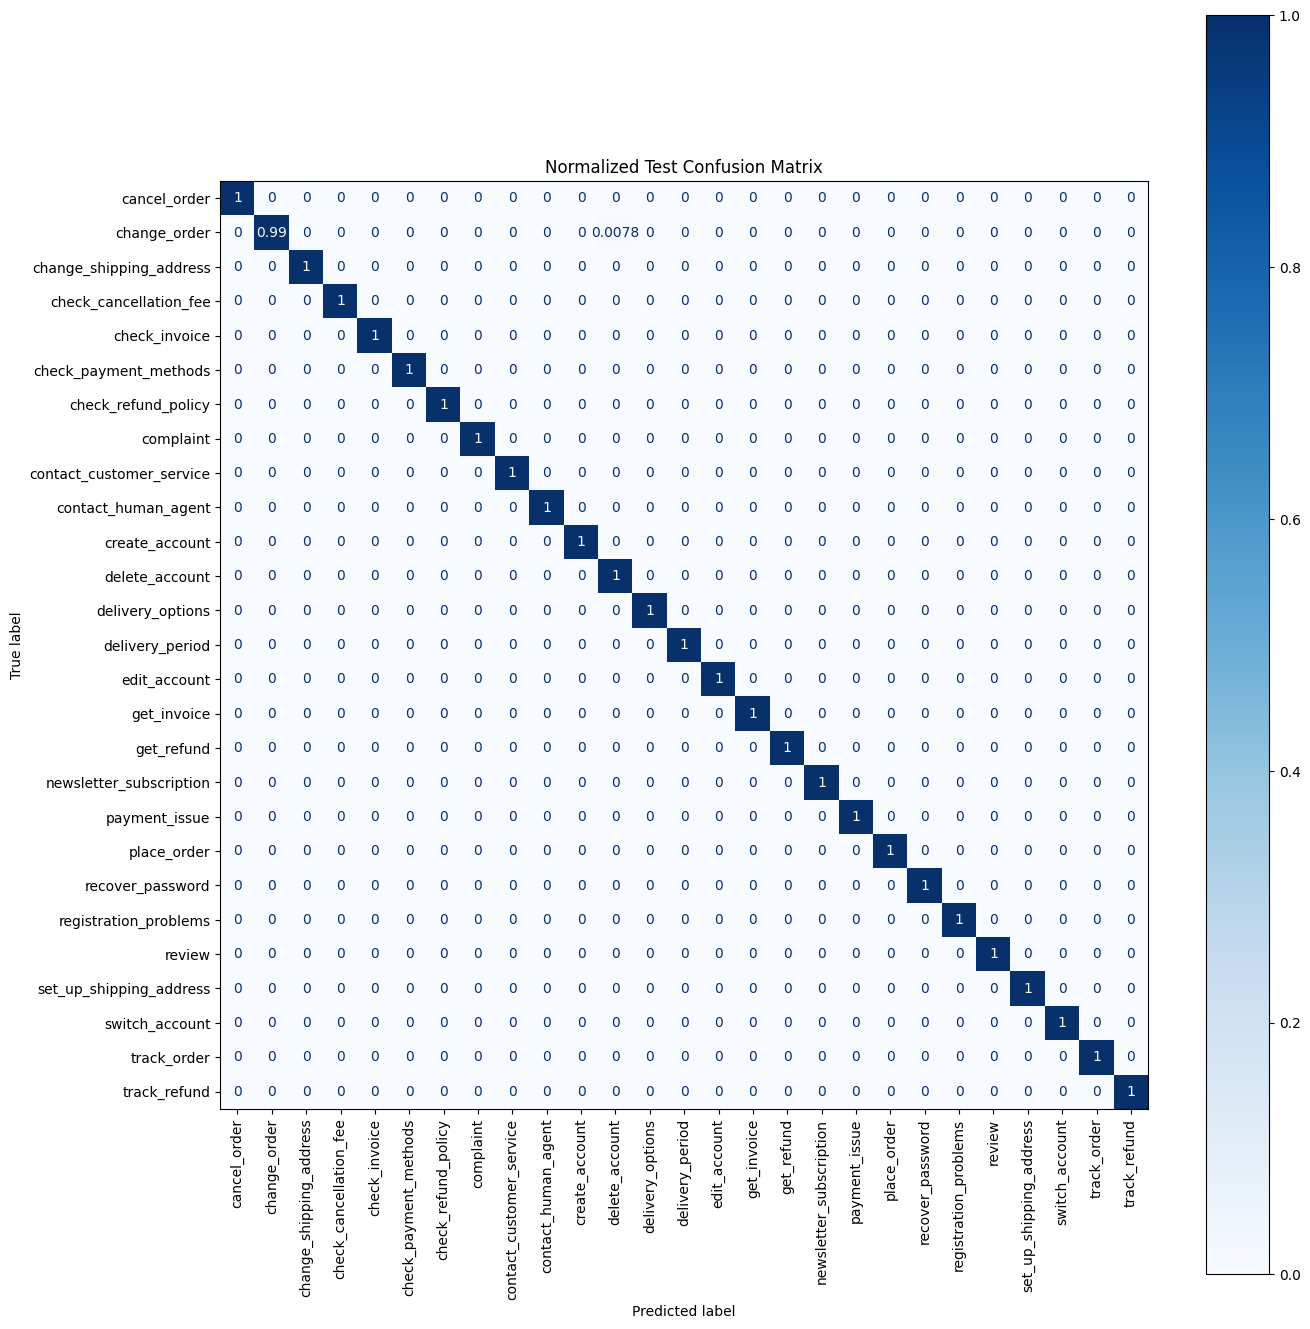

In [11]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

report = classification_report(
    y_test, test_predictions, output_dict=True, zero_division=0
)
display(pd.DataFrame(report).transpose().round(4))

fig, ax = plt.subplots(figsize=(14, 14))
ConfusionMatrixDisplay.from_predictions(
    y_test, test_predictions, normalize="true",
    xticks_rotation=90, cmap="Blues", ax=ax
)
ax.set_title("Normalized Test Confusion Matrix")
plt.tight_layout()
plt.show()